<h2> Regression </h2>

* Distance based : Linear, Polynomial, ridge,lasso,
* Tree Bases: Descision Tree, Random Forest
* 

In [109]:
import sys
print("Python Home:", sys.prefix)

Python Home: C:\Users\ak434\anaconda3


#### OneHotEncoder is a technique used to convert categorical data (text or labels) into numerical values so that a machine learning model can understand them.

In [110]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from statsmodels.stats.outliers_influence import variance_inflation_factor

# building the model, Calling the respective algorithm
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor 
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR #support vector regressor

# post processing
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

#deployment
import joblib

# ignore unneccesary warnings
import warnings
warnings.filterwarnings("ignore")

In [111]:
# import raw data
link = "https://raw.githubusercontent.com/swapnilsaurav/MachineLearning/refs/heads/master/Examples/Regression/ml_regression_property_dataset.csv"
df = pd.read_csv(link)

df.head()
df.shape
print('Columns Names:', df.columns.tolist())

Columns Names: ['Property_ID', 'Listing_Date', 'City', 'Locality', 'Property_Type', 'BHK', 'Built_Up_Area_sqft', 'Carpet_Area_sqft', 'Age_Years', 'Floor', 'Total_Floors', 'Bathrooms', 'Parking_Spaces', 'Furnishing_Status', 'Facing', 'Gated_Community', 'Distance_to_Metro_km', 'Distance_to_CBD_km', 'Nearby_Schools', 'Crime_Index', 'Amenities_Score', 'Monthly_Maintenance_INR', 'Seller_Type', 'Loan_Available', 'Annual_Property_Tax_INR', 'Price_Lakhs']


### ML objective is to predict Residential Property price based on locarion, area, property characteristics

In [112]:
target_column = "Price_lakhs"
print("Target Column:", target_column)

Target Column: Price_lakhs


In [113]:
# Data Preperation
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Property_ID              1000 non-null   object 
 1   Listing_Date             1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Locality                 1000 non-null   object 
 4   Property_Type            1000 non-null   object 
 5   BHK                      1000 non-null   int64  
 6   Built_Up_Area_sqft       975 non-null    float64
 7   Carpet_Area_sqft         946 non-null    float64
 8   Age_Years                959 non-null    float64
 9   Floor                    1000 non-null   object 
 10  Total_Floors             1000 non-null   int64  
 11  Bathrooms                1000 non-null   int64  
 12  Parking_Spaces           1000 non-null   int64  
 13  Furnishing_Status        966 non-null    object 
 14  Facing                   

### Data Preprocessing
* some data types are marked as Object. These needed to be fixed.
* some columns have null values. that is needed to be fixed
* duplicate records

In [114]:
missing_values = df.isnull().sum()
#print(missing_values)

missing_pct = (missing_values / len(df))*100
print("Only columns with Missing Values :\n",missing_pct[missing_pct>0])


print("\n\n\nCheck duplicate Records:")
duplicate_count = df.duplicated().sum()
print(duplicate_count)

Only columns with Missing Values :
 Built_Up_Area_sqft      2.5
Carpet_Area_sqft        5.4
Age_Years               4.1
Furnishing_Status       3.4
Distance_to_Metro_km    6.1
Crime_Index             3.0
Amenities_Score         2.5
Seller_Type             1.9
dtype: float64



Check duplicate Records:
10


In [115]:
# Display Duplicate Rows
df_dup = df[df.duplicated(keep = False)].sort_values(by='Property_ID')
print(df_dup)

    Property_ID Listing_Date       City         Locality      Property_Type  \
144  PROP-10145   2025-12-06  Hyderabad         Kondapur          Apartment   
944  PROP-10145   2025-12-06  Hyderabad         Kondapur          Apartment   
969  PROP-10388   2025-10-01  Hyderabad       Kukatpally          Apartment   
387  PROP-10388   2025-10-01  Hyderabad       Kukatpally          Apartment   
927  PROP-10410   2025-10-29  Delhi NCR         Gurugram  Independent House   
409  PROP-10410   2025-10-29  Delhi NCR         Gurugram  Independent House   
410  PROP-10411   2026-03-03  Delhi NCR           Dwarka          Apartment   
902  PROP-10411   2026-03-03  Delhi NCR           Dwarka          Apartment   
549  PROP-10550   2026-03-17  Delhi NCR            Noida          Apartment   
937  PROP-10550   2026-03-17  Delhi NCR            Noida          Apartment   
911  PROP-10647   2025-05-20       Pune            Wakad          Apartment   
646  PROP-10647   2025-05-20       Pune            W

In [116]:
# Remove the Duplicates
df = df.drop_duplicates().reset_index(drop=True)
df.shape

# some duplicate rows have been deleted

(990, 26)

In [117]:
# checking the unique values
categorical_columns_1 = df.select_dtypes(include = ['object'])
for column in categorical_columns_1:
    print("Column:", column)
    print(df[column].unique(),"\n")

Column: Property_ID
['PROP-10001' 'PROP-10002' 'PROP-10003' 'PROP-10004' 'PROP-10005'
 'PROP-10006' 'PROP-10007' 'PROP-10008' 'PROP-10009' 'PROP-10010'
 'PROP-10011' 'PROP-10012' 'PROP-10013' 'PROP-10014' 'PROP-10015'
 'PROP-10016' 'PROP-10017' 'PROP-10018' 'PROP-10019' 'PROP-10020'
 'PROP-10021' 'PROP-10022' 'PROP-10023' 'PROP-10024' 'PROP-10025'
 'PROP-10026' 'PROP-10027' 'PROP-10028' 'PROP-10029' 'PROP-10030'
 'PROP-10031' 'PROP-10032' 'PROP-10033' 'PROP-10034' 'PROP-10035'
 'PROP-10036' 'PROP-10037' 'PROP-10038' 'PROP-10039' 'PROP-10040'
 'PROP-10041' 'PROP-10042' 'PROP-10043' 'PROP-10044' 'PROP-10045'
 'PROP-10046' 'PROP-10047' 'PROP-10048' 'PROP-10049' 'PROP-10050'
 'PROP-10051' 'PROP-10052' 'PROP-10053' 'PROP-10054' 'PROP-10055'
 'PROP-10056' 'PROP-10057' 'PROP-10058' 'PROP-10059' 'PROP-10060'
 'PROP-10061' 'PROP-10062' 'PROP-10063' 'PROP-10064' 'PROP-10065'
 'PROP-10066' 'PROP-10067' 'PROP-10068' 'PROP-10069' 'PROP-10070'
 'PROP-10071' 'PROP-10072' 'PROP-10073' 'PROP-10074' 'PR

In [118]:
# On checking the uniqueness: found some irregularities in Columns 
# : City, Floor, Furnishing_Status,Gated_Community


# First Clean City
df['City'] = (df['City'].astype(str).str.strip().str.title().str.replace('Ncr', 'NCR', regex = False))

categorical_columns_1 = df.select_dtypes(include = ['object'])
for column in categorical_columns_1:
    print("Column:", column)
    print(df[column].unique(),"\n")

Column: Property_ID
['PROP-10001' 'PROP-10002' 'PROP-10003' 'PROP-10004' 'PROP-10005'
 'PROP-10006' 'PROP-10007' 'PROP-10008' 'PROP-10009' 'PROP-10010'
 'PROP-10011' 'PROP-10012' 'PROP-10013' 'PROP-10014' 'PROP-10015'
 'PROP-10016' 'PROP-10017' 'PROP-10018' 'PROP-10019' 'PROP-10020'
 'PROP-10021' 'PROP-10022' 'PROP-10023' 'PROP-10024' 'PROP-10025'
 'PROP-10026' 'PROP-10027' 'PROP-10028' 'PROP-10029' 'PROP-10030'
 'PROP-10031' 'PROP-10032' 'PROP-10033' 'PROP-10034' 'PROP-10035'
 'PROP-10036' 'PROP-10037' 'PROP-10038' 'PROP-10039' 'PROP-10040'
 'PROP-10041' 'PROP-10042' 'PROP-10043' 'PROP-10044' 'PROP-10045'
 'PROP-10046' 'PROP-10047' 'PROP-10048' 'PROP-10049' 'PROP-10050'
 'PROP-10051' 'PROP-10052' 'PROP-10053' 'PROP-10054' 'PROP-10055'
 'PROP-10056' 'PROP-10057' 'PROP-10058' 'PROP-10059' 'PROP-10060'
 'PROP-10061' 'PROP-10062' 'PROP-10063' 'PROP-10064' 'PROP-10065'
 'PROP-10066' 'PROP-10067' 'PROP-10068' 'PROP-10069' 'PROP-10070'
 'PROP-10071' 'PROP-10072' 'PROP-10073' 'PROP-10074' 'PR

In [119]:
# Furnishing_Status
df['Furnishing_Status'] = (
    df['Furnishing_Status'].astype(str).str.strip().str.title().str.replace('-',' ', regex = False))
df['Furnishing_Status'] = df['Furnishing_Status'].replace('Nan', np.nan)

# Gated_Community
df['Gated_Community'] = (
    df['Gated_Community'].astype(str).str.strip().str.title().replace({'Y':'Yes',
                                                                      'Noo':'No'}))


### For floor cleaning
* creating a function as we have multiple values to clean.
* and all are string so, it is needed to be converted in integer

In [120]:
# Column: Floor : 'Ground' '6' '8' '11' '3rd' '7' '3' '14' '9' '5' '2nd' '19' '21' '1'
 # '1st' '17' '29' '26' '4' '27' '20' '2' '15' '18' '12' '31' '13' '10' '16'
 # '24' '30' '23' '28' '25' '22' '32' '33' '34'] 

def clean_floor_data(value):
    if pd.isna(value):
        return np.nan
    if value.lower() == 'ground':
        return 0
    value = (value
        .replace("st","")
        .replace("nd","")
        .replace("rd","")
        .replace("th","")
    )
    try:
        return int(value)
    except:
        return np.nan

df['Floor_Numeric'] = df['Floor'].apply(clean_floor_data)

In [121]:
# checking the value and comparing with original
df[['Floor', 'Floor_Numeric']].head(10)

columns_to_drop = ['Floor','Property_ID']

In [122]:
df.columns

Index(['Property_ID', 'Listing_Date', 'City', 'Locality', 'Property_Type',
       'BHK', 'Built_Up_Area_sqft', 'Carpet_Area_sqft', 'Age_Years', 'Floor',
       'Total_Floors', 'Bathrooms', 'Parking_Spaces', 'Furnishing_Status',
       'Facing', 'Gated_Community', 'Distance_to_Metro_km',
       'Distance_to_CBD_km', 'Nearby_Schools', 'Crime_Index',
       'Amenities_Score', 'Monthly_Maintenance_INR', 'Seller_Type',
       'Loan_Available', 'Annual_Property_Tax_INR', 'Price_Lakhs',
       'Floor_Numeric'],
      dtype='object')

In [123]:
# Step 3 DATA Wrangling
# Feature Engineering

df['Listing_Date'] = pd.to_datetime(df['Listing_Date'],errors = "coerce")

df['Listing_Year'] = df['Listing_Date'].dt.year
df['Listing_month'] = df['Listing_Date'].dt.month
df['Listing_Quater']= df['Listing_Date'].dt.quarter

# creating the reference Date
reference_date = df['Listing_Date'].max()
df['Days_since_Listing'] = (reference_date - df['Listing_Date']).dt.days

columns_to_drop.append('Listing_Date')

### EDA 
* we visualize the data to understand relationship betweern different feature and also target variable

In [124]:
#df.shape
df.columns

Index(['Property_ID', 'Listing_Date', 'City', 'Locality', 'Property_Type',
       'BHK', 'Built_Up_Area_sqft', 'Carpet_Area_sqft', 'Age_Years', 'Floor',
       'Total_Floors', 'Bathrooms', 'Parking_Spaces', 'Furnishing_Status',
       'Facing', 'Gated_Community', 'Distance_to_Metro_km',
       'Distance_to_CBD_km', 'Nearby_Schools', 'Crime_Index',
       'Amenities_Score', 'Monthly_Maintenance_INR', 'Seller_Type',
       'Loan_Available', 'Annual_Property_Tax_INR', 'Price_Lakhs',
       'Floor_Numeric', 'Listing_Year', 'Listing_month', 'Listing_Quater',
       'Days_since_Listing'],
      dtype='object')

In [125]:
df.drop(columns=['Property_ID','Listing_Date','Floor'], inplace = True)

Property Price Distribution


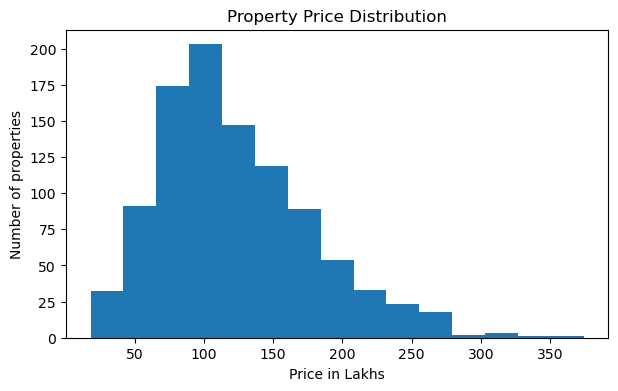

In [126]:
print("Property Price Distribution")
plt.figure(figsize=(7,4))
plt.hist(df['Price_Lakhs'],bins = 15)
plt.xlabel('Price in Lakhs')
plt.ylabel('Number of properties')
plt.title('Property Price Distribution')
plt.show()


Property price by City


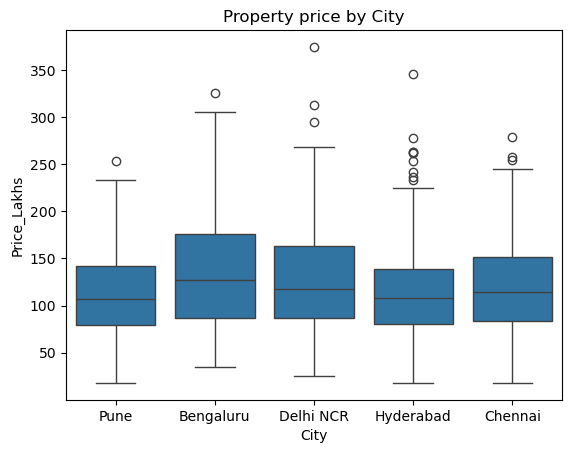

In [127]:
print('Property price by City')
sns.boxplot(data = df, x='City',y='Price_Lakhs')

plt.title("Property price by City")
plt.show()

Average price per BHK


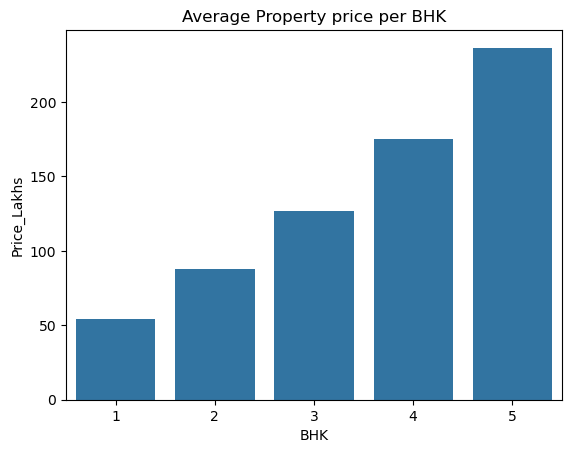

In [128]:
print("Average price per BHK")
sns.barplot(data = df, x='BHK',y='Price_Lakhs', errorbar=None)

plt.title("Average Property price per BHK")
plt.show()


Furnishing With price


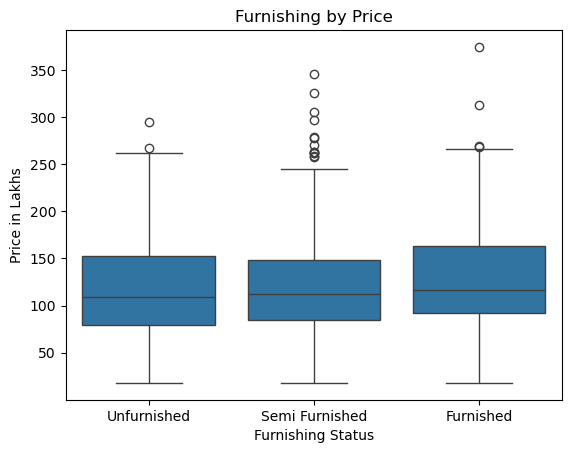

In [129]:
print('Furnishing With price')
sns.boxplot(data = df, x='Furnishing_Status',y='Price_Lakhs')

plt.title("Furnishing by Price")
plt.xlabel('Furnishing Status')
plt.ylabel('Price in Lakhs')
plt.show()

Price of property Type


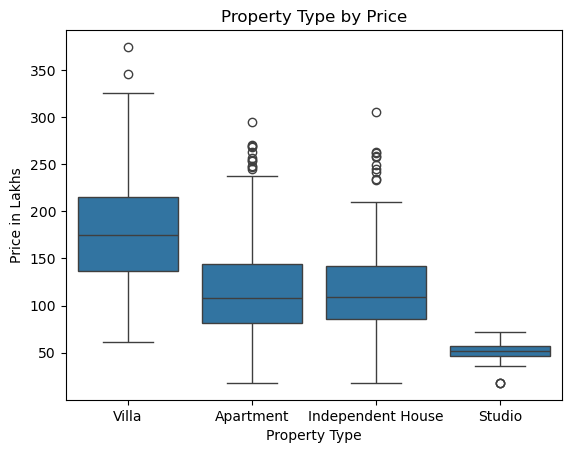

In [130]:
print("Price of property Type")
sns.boxplot(data = df, x='Property_Type',y='Price_Lakhs')

plt.title("Property Type by Price")
plt.xlabel('Property Type')
plt.ylabel('Price in Lakhs')
plt.show()

Age of Property vs Price


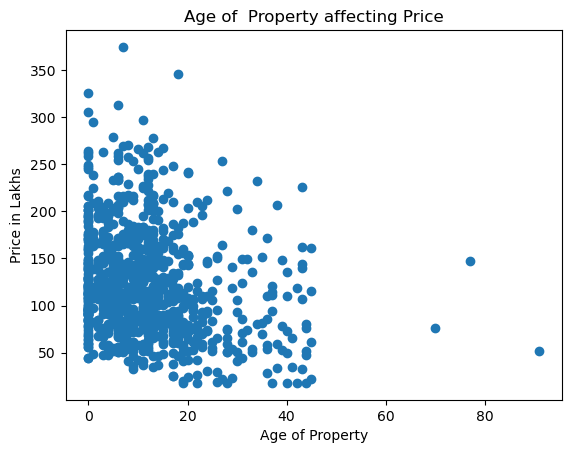

In [131]:
print("Age of Property vs Price")
plt.scatter(df['Age_Years'], df['Price_Lakhs'])
plt.title("Age of  Property affecting Price")
plt.xlabel('Age of Property')
plt.ylabel('Price in Lakhs')
plt.show()

In [132]:
df.columns

Index(['City', 'Locality', 'Property_Type', 'BHK', 'Built_Up_Area_sqft',
       'Carpet_Area_sqft', 'Age_Years', 'Total_Floors', 'Bathrooms',
       'Parking_Spaces', 'Furnishing_Status', 'Facing', 'Gated_Community',
       'Distance_to_Metro_km', 'Distance_to_CBD_km', 'Nearby_Schools',
       'Crime_Index', 'Amenities_Score', 'Monthly_Maintenance_INR',
       'Seller_Type', 'Loan_Available', 'Annual_Property_Tax_INR',
       'Price_Lakhs', 'Floor_Numeric', 'Listing_Year', 'Listing_month',
       'Listing_Quater', 'Days_since_Listing'],
      dtype='object')

In [133]:
print("Checking Multicolinearity")
corr_df = df[['BHK','Built_Up_Area_sqft',
       'Carpet_Area_sqft',
            'Monthly_Maintenance_INR','Annual_Property_Tax_INR' ]].corr()
print(corr_df)

Checking Multicolinearity
                              BHK  Built_Up_Area_sqft  Carpet_Area_sqft  \
BHK                      1.000000            0.498809          0.874344   
Built_Up_Area_sqft       0.498809            1.000000          0.551675   
Carpet_Area_sqft         0.874344            0.551675          1.000000   
Monthly_Maintenance_INR  0.318653            0.191849          0.385823   
Annual_Property_Tax_INR  0.760420            0.491377          0.844931   

                         Monthly_Maintenance_INR  Annual_Property_Tax_INR  
BHK                                     0.318653                 0.760420  
Built_Up_Area_sqft                      0.191849                 0.491377  
Carpet_Area_sqft                        0.385823                 0.844931  
Monthly_Maintenance_INR                 1.000000                 0.316638  
Annual_Property_Tax_INR                 0.316638                 1.000000  


In [134]:
df.isnull().sum()

City                        0
Locality                    0
Property_Type               0
BHK                         0
Built_Up_Area_sqft         25
Carpet_Area_sqft           54
Age_Years                  40
Total_Floors                0
Bathrooms                   0
Parking_Spaces              0
Furnishing_Status          34
Facing                      0
Gated_Community             0
Distance_to_Metro_km       60
Distance_to_CBD_km          0
Nearby_Schools              0
Crime_Index                29
Amenities_Score            25
Monthly_Maintenance_INR     0
Seller_Type                19
Loan_Available              0
Annual_Property_Tax_INR     0
Price_Lakhs                 0
Floor_Numeric               0
Listing_Year                0
Listing_month               0
Listing_Quater              0
Days_since_Listing          0
dtype: int64

In [135]:
# VIF variance Inflation Factor
vif_columns_df = df[['Built_Up_Area_sqft','BHK','Carpet_Area_sqft','Age_Years','Bathrooms',
                    'Parking_Spaces','Monthly_Maintenance_INR','Annual_Property_Tax_INR',
                   'Distance_to_Metro_km','Distance_to_CBD_km']]

#first checing the misssing values then filling with median

for column in vif_columns_df.columns:
    vif_columns_df[column] = vif_columns_df[column].fillna(
        vif_columns_df[column].median()
    )

vif_result = pd.DataFrame()
vif_result['Feature'] = vif_columns_df.columns

vif_result['VIF'] = [
    variance_inflation_factor(vif_columns_df.values,i)
    for i in range(vif_columns_df.shape[1])
]
print(vif_result)

                   Feature        VIF
0       Built_Up_Area_sqft   4.119198
1                      BHK  48.349777
2         Carpet_Area_sqft  32.152075
3                Age_Years   2.150201
4                Bathrooms  25.813370
5           Parking_Spaces   3.152146
6  Monthly_Maintenance_INR   2.175807
7  Annual_Property_Tax_INR  14.496363
8     Distance_to_Metro_km   2.221923
9       Distance_to_CBD_km   3.970438


In [136]:
vif_columns_df.isnull().sum()

Built_Up_Area_sqft         0
BHK                        0
Carpet_Area_sqft           0
Age_Years                  0
Bathrooms                  0
Parking_Spaces             0
Monthly_Maintenance_INR    0
Annual_Property_Tax_INR    0
Distance_to_Metro_km       0
Distance_to_CBD_km         0
dtype: int64

In [137]:
# Seperate Features and Target

x = df.drop(columns = ['Price_Lakhs'])
y = df['Price_Lakhs']

print("X shape:", x.shape)
print("Y Shape:", y.shape)

print("Train Test Split")
X_train, X_test , Y_train, Y_test = train_test_split(x,y, test_size= 0.20)

print("X_train shape:", X_train.shape)
print("Y_train Shape:", Y_train.shape)
print("X_test shape:", X_test.shape)
print("Y_test Shape:", Y_test.shape)


X shape: (990, 27)
Y Shape: (990,)
Train Test Split
X_train shape: (792, 27)
Y_train Shape: (792,)
X_test shape: (198, 27)
Y_test Shape: (198,)


In [138]:
# Numerical Features
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()

# Numerical Preprocessing Pipeline
numeric_transformer = Pipeline(steps = [("imputer",SimpleImputer(strategy='median')),
                                        ("scaler",StandardScaler() )])
# Categorical Features
categorical_features = X_train.select_dtypes(exclude = np.number).columns.tolist()

categorical_transformer = Pipeline(steps = [("imputer",SimpleImputer(strategy='most_frequent')),
                                        ("encoder",OneHotEncoder(handle_unknown= "ignore") )])

In [139]:
# column transformer

preprocessor = ColumnTransformer(
    transformers= [('numeric', numeric_transformer, numerical_features),
                  'categorical',categorical_transformer,categorical_features]
)

In [140]:
# Creating the baseline Model
baseline_prediction = np.repeat(Y_train.mean(), len(Y_test))

In [141]:
# Model Evaluation

baseline_mae = mean_absolute_error(Y_test,baseline_prediction)
baseline_mse = mean_squared_error(Y_test, baseline_prediction)

baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(Y_test, baseline_prediction)

print("baseline MAE",baseline_mae)
print("baseline RMSE",baseline_rmse)
print("baseline R2",baseline_r2)


baseline MAE 42.19657330884604
baseline RMSE 54.05437908497161
baseline R2 -0.0007000888775197112


In [142]:
df.columns

Index(['City', 'Locality', 'Property_Type', 'BHK', 'Built_Up_Area_sqft',
       'Carpet_Area_sqft', 'Age_Years', 'Total_Floors', 'Bathrooms',
       'Parking_Spaces', 'Furnishing_Status', 'Facing', 'Gated_Community',
       'Distance_to_Metro_km', 'Distance_to_CBD_km', 'Nearby_Schools',
       'Crime_Index', 'Amenities_Score', 'Monthly_Maintenance_INR',
       'Seller_Type', 'Loan_Available', 'Annual_Property_Tax_INR',
       'Price_Lakhs', 'Floor_Numeric', 'Listing_Year', 'Listing_month',
       'Listing_Quater', 'Days_since_Listing'],
      dtype='object')

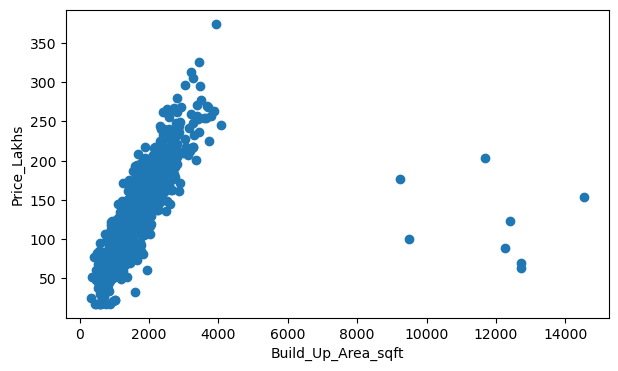

Building simple linear Regression
Slr Eqn: Y = [0.0314547] X + [73.26070523]


In [143]:
# Simple Linear Regression

simple_data = df[['Built_Up_Area_sqft','Price_Lakhs']].dropna()
plt.figure(figsize=(7,4))
plt.scatter(simple_data['Built_Up_Area_sqft'],simple_data['Price_Lakhs'])
plt.ylabel('Price_Lakhs')
plt.xlabel('Build_Up_Area_sqft')

plt.show()

X_train, X_test , Y_train, Y_test = train_test_split(
    simple_data[['Built_Up_Area_sqft']],simple_data[['Price_Lakhs']], test_size= 0.20)


print("Building simple linear Regression")
slr_model = LinearRegression()
slr_model.fit(X_train,Y_train)
c = slr_model.intercept_
m = slr_model.coef_[0]
print(f"Slr Eqn: Y = {m} X + {c}")


In [144]:
slr_pred = slr_model.predict(X_test)

In [145]:
# Model Evaluation

slr_mae = mean_absolute_error(Y_test, slr_pred)
slr_mse = mean_squared_error(Y_test, slr_pred)
slr_rmse = np.sqrt(slr_mse)
slr_r2 = r2_score(Y_test,slr_pred)

In [146]:
print(slr_mae)
print(slr_r2)
print(slr_rmse)

34.052220381018415
-0.22545407696235387
59.924660898363975


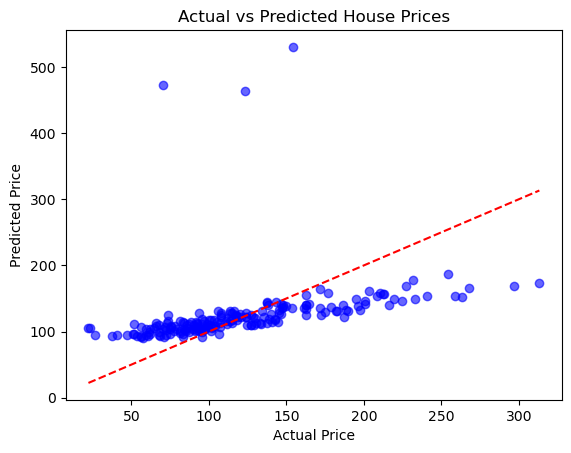

In [147]:
plt.scatter(Y_test, slr_pred, color='blue', alpha=0.6)
plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    color='red',
    linestyle='--'
)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [148]:
# Multiple Linear Regression

X = df[['Carpet_Area_sqft','BHK','Bathrooms']]
Y = df['Price_Lakhs']

mlr = LinearRegression()
mlr.fit(X_train,Y_train)

mlr_pred = mlr.predict(X_test)

mlr_mae = mean_absolute_error(Y_test,mlr_pred)
mlr_mse = mean_squared_error(Y_test,mlr_pred)
mlr_rmse = np.sqrt(mlr_mse)
mlr_r2 = r2_score(Y_test,mlr_pred)

print("MAE:", mlr_mae)
print("MSE:", mlr_mse)
print("RMSE:", mlr_rmse)
print("R2 Score:", mlr_r2)

MAE: 34.052220381018415
MSE: 3590.964983783912
RMSE: 59.924660898363975
R2 Score: -0.22545407696235387


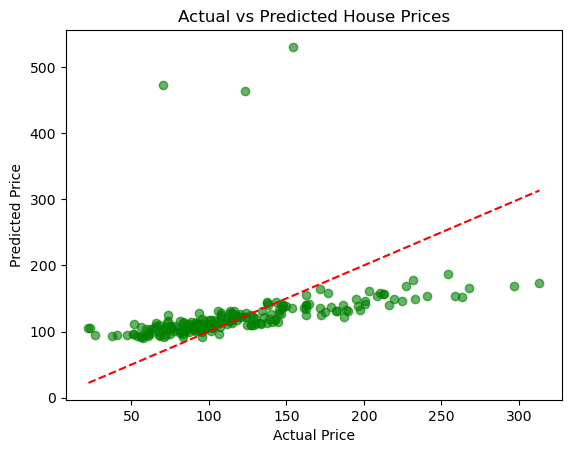

In [149]:
plt.scatter(Y_test, mlr_pred, color = 'green', alpha = 0.6)
plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    color='red',
    linestyle='--'
)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [151]:
print("Y_test shape:", Y_test.shape)
print("mlr_pred shape:", mlr_pred.shape)

Y_test shape: (193, 1)
mlr_pred shape: (193, 1)


In [174]:
poly_data = df[['Carpet_Area_sqft','Price_Lakhs']].dropna()
X_train, X_test, Y_train, Y_test = train_test_split(
    poly_data[['Carpet_Area_sqft']], poly_data[['Price_Lakhs']], test_size=0.2, random_state=42
)

# creating Polynomila features
poly = PolynomialFeatures(
    degree=2, include_bias=False
)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly,Y_train)

poly_pred = poly_model.predict(X_test_poly)

In [175]:
poly_mae = mean_absolute_error(Y_test, poly_pred)

poly_mse = mean_squared_error(Y_test, poly_pred)

poly_rmse = np.sqrt(poly_mse)

poly_r2 = r2_score(Y_test, poly_pred)

print("MAE:", poly_mae)
print("MSE:", poly_mse)
print("RMSE:", poly_rmse)
print("R2 Score:", poly_r2)

MAE: 21.111361358935
MSE: 737.3654005612415
RMSE: 27.154472938380547
R2 Score: 0.7358215161783097


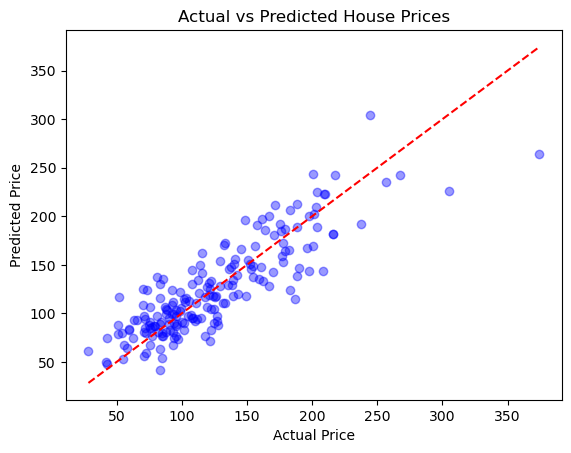

In [176]:
plt.scatter(Y_test, poly_pred, color = 'blue', alpha = 0.4)
plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    color='red',
    linestyle='--'
)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [177]:
correlation = df.corr(numeric_only=True)

print(
    correlation['Price_Lakhs']
    .sort_values(ascending=False)
)

Price_Lakhs                1.000000
Carpet_Area_sqft           0.883670
BHK                        0.839169
Annual_Property_Tax_INR    0.805883
Bathrooms                  0.761335
Built_Up_Area_sqft         0.507885
Monthly_Maintenance_INR    0.330521
Amenities_Score            0.145348
Listing_Quater             0.058250
Listing_month              0.058242
Parking_Spaces             0.057562
Listing_Year               0.009511
Nearby_Schools            -0.004022
Crime_Index               -0.022797
Days_since_Listing        -0.045654
Distance_to_Metro_km      -0.055915
Distance_to_CBD_km        -0.071551
Floor_Numeric             -0.107133
Total_Floors              -0.133514
Age_Years                 -0.219964
Name: Price_Lakhs, dtype: float64


In [240]:
ridge_data = df[['Carpet_Area_sqft',
                 'BHK',
                 'Annual_Property_Tax_INR',
                 'Bathrooms','Price_Lakhs']].dropna()
X_train, X_test, Y_train, Y_test = train_test_split(
    ridge_data[['Carpet_Area_sqft',
                 'BHK',
                 'Annual_Property_Tax_INR',
                 'Bathrooms']],ridge_data[['Price_Lakhs']], test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_Scaled = scaler.fit_transform(X_train)
X_test_Scaled = scaler.transform(X_test)

ridge_model = Ridge(alpha=15.0)
ridge_model.fit(X_train_Scaled,Y_train)

ridge_pred = ridge_model.predict(X_test_Scaled)

In [241]:
ridge_mae = mean_absolute_error(Y_test, ridge_pred)

ridge_mse = mean_squared_error(Y_test, ridge_pred)

ridge_rmse = np.sqrt(ridge_mse)

ridge_r2 = r2_score(Y_test, ridge_pred)

print("MAE:", ridge_mae)
print("MSE:", ridge_mse)
print("RMSE:", ridge_rmse)
print("R2 Score:", ridge_r2)

MAE: 18.763014411309854
MSE: 603.3406253678774
RMSE: 24.562993005085463
R2 Score: 0.7838390416523506


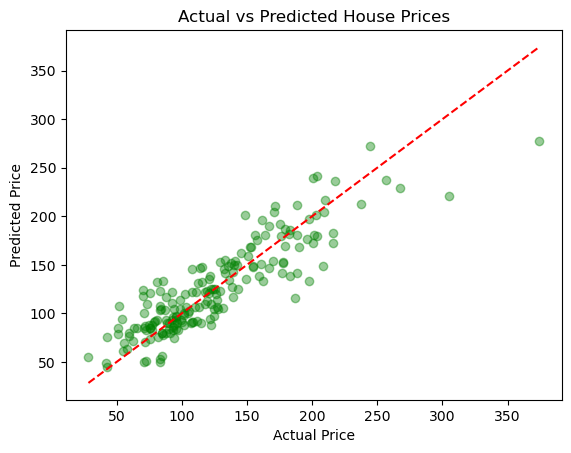

In [243]:
plt.scatter(Y_test, ridge_pred, color = 'green', alpha = 0.4)
plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    color='red',
    linestyle='--'
)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted House Prices")

plt.show()